# 03 — Kiểm định giả thuyết thống kê

**Người phụ trách:** TV3 — Sang · **Báo cáo:** Chương 3, mục 3.2 · **Dữ liệu:** `cleaned_cars.csv` v1.0 (6.693 dòng × 22 cột)

Notebook trả lời các câu hỏi nghiên cứu CH2 – CH4 trong `docs/quy_uoc_nhom.md`:

* **CH2** — Giá xe số tự động có cao hơn xe số sàn không?
* **CH3** — Giá có khác nhau theo nhiên liệu (`fuel_group`) và theo số đời chủ (`owner`) không?
* **CH4** — Nhiên liệu và loại hộp số có độc lập không?

**Quy ước:** α = 0,05 · `random_state = 42` · giá tính bằng INR · kiểm định trên `log_price = ln(selling_price)` ·
nhiên liệu dùng `fuel_group` (CNG và LPG đã gộp). Đánh số **tiếp theo mục 3.1** (TV2 dùng Hình 3.1 – 3.6, Bảng 3.1 – 3.4):
mục 3.2 dùng **Hình 3.7 – 3.11** và **Bảng 3.5 – 3.12**, lưu vào `figures/03_hypothesis/` (hình 300 dpi, bảng `.csv`).

Welch ANOVA, Games-Howell và Dunn được cài trực tiếp bằng `scipy` + `statsmodels` (có sẵn trên Kaggle) để notebook
không phụ thuộc gói ngoài; ô cuối cùng kiểm tra chéo với `pingouin` / `scikit-posthocs` nếu máy có cài.

**Mục lục:** 0. Giả thuyết (viết trước khi chạy) · 1. Kiểm tra giả định · 2. Hộp số · 3. Nhiên liệu và số đời chủ ·
4. Chi-bình phương · 5. Bảng tổng hợp (Holm) · 6. Yếu tố gây nhiễu · 7. Số liệu cho báo cáo · 8. Kiểm tra chéo

In [1]:
import warnings
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.multitest import multipletests
from IPython.display import display

ALPHA = 0.05
RANDOM_STATE = 42
matplotlib.rcParams.update({"font.family": "DejaVu Sans", "savefig.dpi": 300, "savefig.bbox": "tight",
                            "axes.spines.top": False, "axes.spines.right": False,
                            "axes.grid": True, "grid.alpha": 0.3, "axes.titlesize": 11, "axes.labelsize": 10})

# Đọc cleaned_cars.csv v1.0 (repo) hoặc từ Kaggle Input
candidates = [Path("../data/processed/cleaned_cars.csv"), Path("data/processed/cleaned_cars.csv"),
              *Path("/kaggle/input").rglob("cleaned_cars.csv")] if Path("/kaggle/input").exists() else \
             [Path("../data/processed/cleaned_cars.csv"), Path("data/processed/cleaned_cars.csv")]
DATA = next(p for p in candidates if p.exists())
df = pd.read_csv(DATA)
assert df.shape == (6693, 22), f"Sai phiên bản cleaned_cars.csv: {df.shape} (cần v1.0 = 6693 x 22)"
FIG_DIR = Path("../figures/03_hypothesis") if not Path("/kaggle/working").exists() else Path("/kaggle/working/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)
print(DATA, df.shape)
df.head()

..\data\processed\cleaned_cars.csv (6693, 22)


,raw_index,name,brand,model,year,car_age,selling_price,log_price,km_driven,fuel,...,is_trustmark,transmission,owner,owner_rank,mileage,mileage_unit,engine,max_power,torque_nm,seats
0,0,Maruti Swift Dzire VDI,Maruti,Swift,2014,6,450000,13.017003,145500,Diesel,...,0,Manual,First Owner,1,23.40,kmpl,1248,74.00,190.00,5
1,1,Skoda Rapid 1.5 TDI Ambition,Skoda,Rapid,2014,6,370000,12.821258,120000,Diesel,...,0,Manual,Second Owner,2,21.14,kmpl,1498,103.52,250.00,5
2,2,Honda City 2017-2020 EXi,Honda,City,2006,14,158000,11.970350,140000,Petrol,...,0,Manual,Third Owner,3,17.70,kmpl,1497,78.00,124.54,5
3,3,Hyundai i20 Sportz Diesel,Hyundai,i20,2010,10,225000,12.323856,127000,Diesel,...,0,Manual,First Owner,1,23.00,kmpl,1396,90.00,219.67,5
4,4,Maruti Swift VXI BSIII,Maruti,Swift,2007,13,130000,11.775290,120000,Petrol,...,0,Manual,First Owner,1,16.10,kmpl,1298,88.20,112.78,5


In [2]:
# Thứ tự mức, nhãn tiếng Việt, màu và các hàm tiện ích dùng chung trong notebook
ORDER = {
    "transmission": ["Manual", "Automatic"],
    "fuel_group": ["Diesel", "Petrol", "CNG/LPG"],
    "owner": ["First Owner", "Second Owner", "Third Owner", "Fourth & Above Owner"],
}
for col, levels in ORDER.items():
    assert set(df[col].unique()) == set(levels), (col, df[col].unique())
assert (df["owner_rank"] == df["owner"].map({lv: i + 1 for i, lv in enumerate(ORDER["owner"])})).all()

LABEL = {"Manual": "Số sàn", "Automatic": "Số tự động",
         "Diesel": "Diesel", "Petrol": "Xăng (Petrol)", "CNG/LPG": "CNG/LPG",
         "First Owner": "1 đời chủ", "Second Owner": "2 đời chủ", "Third Owner": "3 đời chủ",
         "Fourth & Above Owner": "≥ 4 đời chủ"}
VAR_LABEL = {"transmission": "Hộp số", "fuel_group": "Nhiên liệu", "owner": "Số đời chủ"}
COLOR = {"Manual": "#3B6EA5", "Automatic": "#C0504D", "Diesel": "#3B6EA5", "Petrol": "#C0504D",
         "CNG/LPG": "#6A9F58", "First Owner": "#3B6EA5", "Second Owner": "#6A9F58", "Third Owner": "#E39B3B",
         "Fourth & Above Owner": "#C0504D"}
SRC = "Nguồn: CarDekho (Car details v3) — cleaned_cars.csv v1.0; nhóm tính toán trong notebooks/03_hypothesis.ipynb"


def vn(x, d=2):
    # Định dạng số kiểu Việt Nam: dấu chấm phân cách hàng nghìn, dấu phẩy thập phân
    s = f"{x:,.{d}f}"
    return s.replace(",", "§").replace(".", ",").replace("§", ".")


def fmt_p(p):
    return "< 0,001" if p < 0.001 else vn(p, 3)


def p_text(p, label="p"):
    return f"{label} < 0,001" if p < 0.001 else f"{label} = {vn(p, 3)}"


def comma_ticks(ax, axis="y"):
    # Nhãn trục dùng dấu phẩy thập phân theo quy ước báo cáo
    fmt = matplotlib.ticker.FuncFormatter(lambda v, _: f"{v:g}".replace("-", "−").replace(".", ","))
    (ax.yaxis if axis == "y" else ax.xaxis).set_major_formatter(fmt)


def pct(delta):
    # Chênh lệch log -> % chênh lệch giá trung bình hình học: 100 (e^Δ − 1)
    return 100 * (np.exp(delta) - 1)


def save_fig(fig, name, title):
    fig.suptitle(title, fontsize=12.5)
    fig.text(0.01, -0.005, SRC, fontsize=7.5, ha="left", va="top", style="italic", color="#555555")
    fig.savefig(FIG_DIR / f"{name}.png", dpi=300, bbox_inches="tight")
    plt.show()


def save_table(tab, name, title, index=False):
    tab.to_csv(FIG_DIR / f"{name}.csv", index=index, encoding="utf-8-sig")
    print(title)
    display(tab)


def groups_of(col):
    return [df.loc[df[col] == lv, "log_price"].to_numpy() for lv in ORDER[col]]


# Ngưỡng diễn giải hệ số ảnh hưởng — Bảng 2.2 (Cohen, 1988)
def muc_d(x):
    a = abs(x)
    return "không đáng kể" if a < 0.2 else "nhỏ" if a < 0.5 else "vừa" if a < 0.8 else "lớn"


def muc_eta(x):
    return "không đáng kể" if x < 0.01 else "nhỏ" if x < 0.06 else "vừa" if x < 0.14 else "lớn"


def muc_r(x):
    a = abs(x)
    return "không đáng kể" if a < 0.1 else "nhỏ" if a < 0.3 else "vừa" if a < 0.5 else "lớn"


df.groupby(["fuel_group", "transmission"]).size().unstack()

transmission,Automatic,Manual
fuel_group,,
CNG/LPG,NaN,85.0
Diesel,293.0,3358.0
Petrol,273.0,2684.0


## 0. Bảng H0/H1

Viết H0, H1, α = 0,05 cho từng kiểm định **trước khi chạy**.

Ký hiệu $\mu$ là trung bình tổng thể của `log_price`. Vì $e^{\mu}$ là **trung bình hình học** của giá, so sánh $\mu$ giữa các
nhóm tương đương so sánh giá trung bình hình học — đại lượng ít bị chi phối bởi vài xe rất đắt (giá lệch phải mạnh, xem
mục 2.3). Chênh lệch $\Delta$ của `log_price` được quy đổi thành % chênh lệch giá: $100\,(e^{\Delta}-1)\%$.

| KĐ | Câu hỏi | $H_0$ | $H_1$ | Kiểm định chính | Kiểm tra lại | Hệ số ảnh hưởng |
|---|---|---|---|---|---|---|
| KĐ1 | CH2 | $\mu_{\text{tự động}} = \mu_{\text{số sàn}}$ | $\mu_{\text{tự động}} > \mu_{\text{số sàn}}$ (một phía) | Welch t-test | Mann-Whitney U (một phía) | Cohen's $d$; $r$ hạng hai dãy |
| KĐ2 | CH3 | $\mu_{\text{Diesel}} = \mu_{\text{Petrol}} = \mu_{\text{CNG/LPG}}$ | Có ít nhất một cặp khác nhau | Welch ANOVA + Games-Howell | Kruskal-Wallis + Dunn (Holm) | $\eta^2$; $\varepsilon^2$ |
| KĐ3 | CH3 | $\mu_{1} = \mu_{2} = \mu_{3} = \mu_{\ge 4}$ (theo số đời chủ) | Có ít nhất một cặp khác nhau | Welch ANOVA + Games-Howell | Kruskal-Wallis + Dunn (Holm) | $\eta^2$; $\varepsilon^2$ |
| KĐ4 | CH3 | $\rho_s = 0$ giữa `owner_rank` và giá | $\rho_s \ne 0$ (có xu hướng đơn điệu) | Tương quan hạng Spearman | — | $\rho_s$ |
| KĐ5 | CH4 | `fuel_group` và `transmission` độc lập | Hai biến không độc lập | Chi-bình phương (kiểm tra $E_{ij} \ge 5$) | Fisher (bảng 2×2 Diesel–Petrol) | Cramér's $V$ |

* KĐ1 dùng $H_1$ một phía vì CH2 hỏi có hướng ("cao hơn"); KTC 95% của chênh lệch vẫn báo cáo dạng hai phía.
* `owner` là biến **thứ bậc** nên ngoài so sánh nhóm (KĐ3) còn kiểm định xu hướng (KĐ4); `Test Drive Car` đã bị loại ở bước làm sạch.
* **Họ kiểm định chính** KĐ1 – KĐ5 được hiệu chỉnh **Holm** (mục 5). Kiểm định giả định (Shapiro-Wilk, Levene) và kiểm định
  kiểm tra lại (Mann-Whitney, Kruskal-Wallis) không đưa vào họ; hậu kiểm Games-Howell tự kiểm soát sai lầm theo họ trong từng
  biến, Dunn hiệu chỉnh Holm trong từng biến.

In [3]:
bang_3_5 = pd.DataFrame([
    ["KĐ1", "CH2", "μ(tự động) = μ(số sàn)", "μ(tự động) > μ(số sàn) — một phía", "Welch t-test",
     "Mann-Whitney U (một phía)", "Cohen's d; r hạng hai dãy"],
    ["KĐ2", "CH3", "μ(Diesel) = μ(Petrol) = μ(CNG/LPG)", "Có ít nhất một cặp khác nhau",
     "Welch ANOVA + Games-Howell", "Kruskal-Wallis + Dunn (Holm)", "η²; ε²"],
    ["KĐ3", "CH3", "μ bằng nhau ở 4 mức số đời chủ", "Có ít nhất một cặp khác nhau",
     "Welch ANOVA + Games-Howell", "Kruskal-Wallis + Dunn (Holm)", "η²; ε²"],
    ["KĐ4", "CH3", "ρs(owner_rank, giá) = 0", "ρs ≠ 0", "Tương quan Spearman", "—", "r_s"],
    ["KĐ5", "CH4", "fuel_group và transmission độc lập", "Không độc lập",
     "Chi-bình phương (E ≥ 5)", "Fisher 2×2 (Diesel–Petrol)", "Cramér's V"],
], columns=["KĐ", "Câu hỏi", "H0", "H1", "Kiểm định chính", "Kiểm tra lại", "Hệ số ảnh hưởng"])
save_table(bang_3_5, "bang_3_5_gia_thuyet",
           "Bảng 3.5. Giả thuyết của các kiểm định (α = 0,05; μ là trung bình của log_price)")

Bảng 3.5. Giả thuyết của các kiểm định (α = 0,05; μ là trung bình của log_price)


,KĐ,Câu hỏi,H0,H1,Kiểm định chính,Kiểm tra lại,Hệ số ảnh hưởng
0,KĐ1,CH2,μ(tự động) = μ(số sàn),μ(tự động) > μ(số sàn) — một phía,Welch t-test,Mann-Whitney U (một phía),Cohen's d; r hạng hai dãy
1,KĐ2,CH3,μ(Diesel) = μ(Petrol) = μ(CNG/LPG),Có ít nhất một cặp khác nhau,Welch ANOVA + Games-Howell,Kruskal-Wallis + Dunn (Holm),η²; ε²
2,KĐ3,CH3,μ bằng nhau ở 4 mức số đời chủ,Có ít nhất một cặp khác nhau,Welch ANOVA + Games-Howell,Kruskal-Wallis + Dunn (Holm),η²; ε²
3,KĐ4,CH3,"ρs(owner_rank, giá) = 0",ρs ≠ 0,Tương quan Spearman,—,r_s
4,KĐ5,CH4,fuel_group và transmission độc lập,Không độc lập,Chi-bình phương (E ≥ 5),Fisher 2×2 (Diesel–Petrol),Cramér's V


## 1. Kiểm tra giả định

* **Phân phối chuẩn trong từng nhóm:** biểu đồ Q-Q, độ lệch (skewness), độ nhọn dư (excess kurtosis). Với mẫu lớn
  ($n > 300$), độ lệch tuyệt đối $> 2$ hoặc độ nhọn dư $> 7$ mới coi là lệch chuẩn đáng kể (Kim, 2013). Shapiro-Wilk chỉ
  **tham khảo**: với hàng nghìn quan sát nó gần như luôn bác bỏ, và `scipy` cảnh báo p-value không chính xác khi $n > 5.000$
  (nhóm số sàn có 6.127 xe).
* **Đồng nhất phương sai:** Levene dạng trung vị (Brown-Forsythe), $H_0$: phương sai `log_price` bằng nhau giữa các nhóm.

In [4]:
rows = []
for col in ORDER:
    for lv, x in zip(ORDER[col], groups_of(col)):
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")   # scipy cảnh báo khi n > 5.000 — đã ghi chú trong bảng
            sw = stats.shapiro(x)
        rows.append({"Biến": VAR_LABEL[col], "Nhóm": LABEL[lv], "n": len(x),
                     "TB log_price": x.mean(), "ĐLC log_price": x.std(ddof=1),
                     "Độ lệch": stats.skew(x, bias=False), "Độ nhọn dư": stats.kurtosis(x, bias=False),
                     "Shapiro W": sw.statistic, "Shapiro p": sw.pvalue,
                     "Ghi chú": "n > 5.000: p chỉ tham khảo" if len(x) > 5000 else ""})
bang_3_6 = pd.DataFrame(rows)
save_table(bang_3_6, "bang_3_6_gia_dinh_chuan",
           "Bảng 3.6. Kiểm tra giả định phân phối chuẩn của log_price theo từng nhóm")
print(f"Độ lệch tuyệt đối lớn nhất: {bang_3_6['Độ lệch'].abs().max():.3f}; "
      f"độ nhọn dư tuyệt đối lớn nhất: {bang_3_6['Độ nhọn dư'].abs().max():.3f}")
print("Số nhóm Shapiro-Wilk bác bỏ ở α = 0,05:", (bang_3_6["Shapiro p"] <= ALPHA).sum(), "/", len(bang_3_6))

Bảng 3.6. Kiểm tra giả định phân phối chuẩn của log_price theo từng nhóm


,Biến,Nhóm,n,TB log_price,ĐLC log_price,Độ lệch,Độ nhọn dư,Shapiro W,Shapiro p,Ghi chú
0,Hộp số,Số sàn,6127,12.808923,0.690555,-0.538943,0.333898,0.981296,1.112153e-27,n > 5.000: p chỉ tham khảo
1,Hộp số,Số tự động,566,13.748083,0.794470,0.144297,0.143480,0.987415,8.549615e-05,
2,Nhiên liệu,Diesel,3651,13.130787,0.689700,0.031405,0.867121,0.989128,3.929559e-16,
3,Nhiên liệu,Xăng (Petrol),2957,12.602021,0.714066,-0.388137,0.510701,0.980799,1.399801e-19,
4,Nhiên liệu,CNG/LPG,85,12.435326,0.449264,-0.768504,0.423286,0.947625,1.734726e-03,
5,Số đời chủ,1 đời chủ,4165,13.100457,0.669763,-0.020283,1.580660,0.980296,1.250623e-23,
6,Số đời chủ,2 đời chủ,1883,12.628407,0.722326,-0.109643,0.182008,0.995664,2.947287e-05,
7,Số đời chủ,3 đời chủ,492,12.330263,0.700674,-0.143542,-0.054358,0.995648,1.892077e-01,
8,Số đời chủ,≥ 4 đời chủ,153,12.107844,0.738728,-0.199259,-0.861120,0.975914,8.721134e-03,


Độ lệch tuyệt đối lớn nhất: 0.769; độ nhọn dư tuyệt đối lớn nhất: 1.581
Số nhóm Shapiro-Wilk bác bỏ ở α = 0,05: 8 / 9


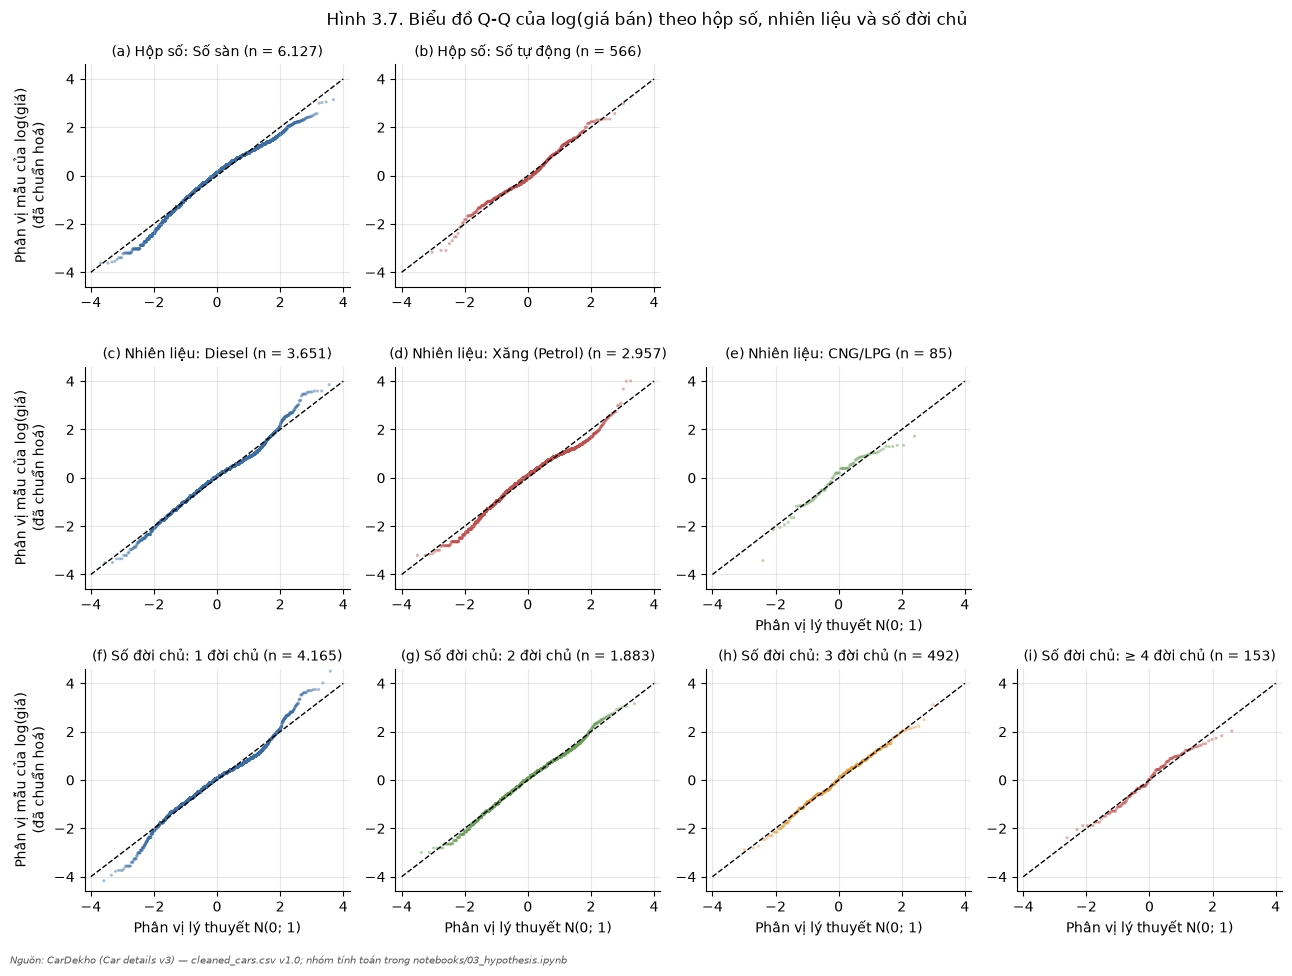

In [5]:
fig, axes = plt.subplots(3, 4, figsize=(13, 9.6))
panel = iter("abcdefghi")
for r, col in enumerate(ORDER):
    for c in range(4):
        ax = axes[r, c]
        if c >= len(ORDER[col]):
            ax.axis("off")
            continue
        lv = ORDER[col][c]
        x = df.loc[df[col] == lv, "log_price"]
        z = (x - x.mean()) / x.std(ddof=1)
        (osm, osr), _ = stats.probplot(z, dist="norm")
        ax.scatter(osm, osr, s=5, alpha=0.45, color=COLOR[lv], edgecolor="none")
        ax.plot([-4, 4], [-4, 4], color="black", lw=1, ls="--")
        ax.set_xlim(-4.2, 4.2)
        ax.set_ylim(-4.6, 4.6)
        ax.set_title(f"({next(panel)}) {VAR_LABEL[col]}: {LABEL[lv]} (n = {vn(len(x), 0)})", fontsize=10)
        if r == 2 or (r == 0 and c >= 2) or (r == 1 and c == 2):
            ax.set_xlabel("Phân vị lý thuyết N(0; 1)")
        if c == 0:
            ax.set_ylabel("Phân vị mẫu của log(giá)\n(đã chuẩn hoá)")
fig.tight_layout(rect=(0, 0, 1, 0.96))
save_fig(fig, "hinh_3_7_qq_plot", "Hình 3.7. Biểu đồ Q-Q của log(giá bán) theo hộp số, nhiên liệu và số đời chủ")

In [6]:
rows = []
for col in ORDER:
    gs = groups_of(col)
    lev = stats.levene(*gs, center="median")
    n = np.array([len(g) for g in gs])
    sd = np.array([g.std(ddof=1) for g in gs])
    k, N = len(gs), n.sum()
    rows.append({"Biến": VAR_LABEL[col], "Số nhóm k": k, "W (Brown-Forsythe)": lev.statistic,
                 "df1": k - 1, "df2": N - k, "p": lev.pvalue,
                 "ĐLC lớn nhất / nhỏ nhất": sd.max() / sd.min(), "Cỡ nhóm lớn nhất / nhỏ nhất": n.max() / n.min(),
                 "Kết luận": "Bác bỏ H0: phương sai khác nhau → dùng phiên bản Welch" if lev.pvalue <= ALPHA
                             else "Chưa bác bỏ H0"})
bang_3_7 = pd.DataFrame(rows)
save_table(bang_3_7, "bang_3_7_levene",
           "Bảng 3.7. Kiểm định Levene (Brown-Forsythe) về đồng nhất phương sai của log_price")

Bảng 3.7. Kiểm định Levene (Brown-Forsythe) về đồng nhất phương sai của log_price


,Biến,Số nhóm k,W (Brown-Forsythe),df1,df2,p,ĐLC lớn nhất / nhỏ nhất,Cỡ nhóm lớn nhất / nhỏ nhất,Kết luận
0,Hộp số,2,18.162358,1,6691,2.056331e-05,1.150480,10.825088,Bác bỏ H0: phương sai khác nhau → dùng phiên b...
1,Nhiên liệu,3,10.895826,2,6690,1.886657e-05,1.589414,42.952941,Bác bỏ H0: phương sai khác nhau → dùng phiên b...
2,Số đời chủ,4,13.957575,3,6689,4.543752e-09,1.102969,27.222222,Bác bỏ H0: phương sai khác nhau → dùng phiên b...


**Nhận xét.** Trên thang log, cả 9 nhóm có độ lệch và độ nhọn dư nhỏ (xem dòng in dưới Bảng 3.6), điểm Q-Q bám sát
đường chéo ở phần thân và chỉ lệch nhẹ ở hai đuôi (Hình 3.7). Shapiro-Wilk vẫn bác bỏ ở phần lớn nhóm — đúng như dự
đoán với cỡ mẫu lớn — nên chỉ dùng tham khảo. Kết hợp với định lý giới hạn trung tâm (nhóm nhỏ nhất CNG/LPG có 85 xe),
giả định chuẩn của trung bình mẫu được chấp nhận. Ngược lại, Levene bác bỏ đồng nhất phương sai ở cả ba biến và cỡ nhóm
lệch rất mạnh (Bảng 3.7), vì vậy:

* hai nhóm → **Welch t-test** (không dùng Student t-test);
* nhiều nhóm → **Welch ANOVA + Games-Howell** (không dùng ANOVA cổ điển + Tukey HSD, chỉ báo cáo ANOVA cổ điển để tham khảo);
* kiểm định phi tham số (Mann-Whitney U, Kruskal-Wallis + Dunn/Holm) để kiểm tra lại độ vững của kết luận.

## 2. Manual vs Automatic (KĐ1)
Welch t-test trên `log_price` (một phía); Mann-Whitney U kiểm tra lại; Cohen's d và hệ số tương quan hạng hai dãy
$r = 2U/(n_1 n_2) - 1$ (Kerby, 2014).

In [7]:
a = df.loc[df["transmission"] == "Automatic", "log_price"]
m = df.loc[df["transmission"] == "Manual", "log_price"]
na, nm = len(a), len(m)

welch = stats.ttest_ind(a, m, equal_var=False, alternative="greater")      # KĐ1: H1 một phía
ci_lo, ci_hi = stats.ttest_ind(a, m, equal_var=False).confidence_interval(0.95)  # KTC 95% hai phía của Δ
diff = a.mean() - m.mean()
s_pooled = np.sqrt(((na - 1) * a.var(ddof=1) + (nm - 1) * m.var(ddof=1)) / (na + nm - 2))
cohen_d = diff / s_pooled
mw = stats.mannwhitneyu(a, m, alternative="greater")
r_rb = 2 * mw.statistic / (na * nm) - 1

kd1 = {"t": welch.statistic, "df": welch.df, "p": welch.pvalue, "diff": diff, "ci": (ci_lo, ci_hi),
       "d": cohen_d, "U": mw.statistic, "p_mw": mw.pvalue, "r_rb": r_rb}

mo_ta = df.groupby("transmission").agg(n=("log_price", "size"), tb_log=("log_price", "mean"),
                                       dlc_log=("log_price", "std"), trung_vi_gia=("selling_price", "median"))
mo_ta["tb_hinh_hoc_gia"] = np.exp(mo_ta["tb_log"])
display(mo_ta.loc[ORDER["transmission"]])
print(f"Welch t = {welch.statistic:.3f}, df = {welch.df:.1f}, p (một phía) = {welch.pvalue:.3e}")
print(f"Δ = {diff:.4f}, KTC 95% [{ci_lo:.4f}; {ci_hi:.4f}] → giá TB hình học của xe số tự động gấp "
      f"{np.exp(diff):.2f} lần (KTC 95%: {np.exp(ci_lo):.2f} – {np.exp(ci_hi):.2f}), tức cao hơn {pct(diff):.1f}% "
      f"({pct(ci_lo):.1f}% – {pct(ci_hi):.1f}%)")
print(f"Cohen's d = {cohen_d:.3f} ({muc_d(cohen_d)})")
print(f"Mann-Whitney U = {mw.statistic:,.1f}, p (một phía) = {mw.pvalue:.3e}, r hạng hai dãy = {r_rb:.3f} ({muc_r(r_rb)})")

,n,tb_log,dlc_log,trung_vi_gia,tb_hinh_hoc_gia
transmission,,,,,
Manual,6127,12.808923,0.690555,400000.0,365463.882909
Automatic,566,13.748083,0.794470,850000.0,934795.550607


Welch t = 27.191, df = 646.3, p (một phía) = 1.985e-109
Δ = 0.9392, KTC 95% [0.8713; 1.0070] → giá TB hình học của xe số tự động gấp 2.56 lần (KTC 95%: 2.39 – 2.74), tức cao hơn 155.8% (139.0% – 173.7%)
Cohen's d = 1.342 (lớn)
Mann-Whitney U = 2,829,186.5, p (một phía) = 3.370e-137, r hạng hai dãy = 0.632 (lớn)


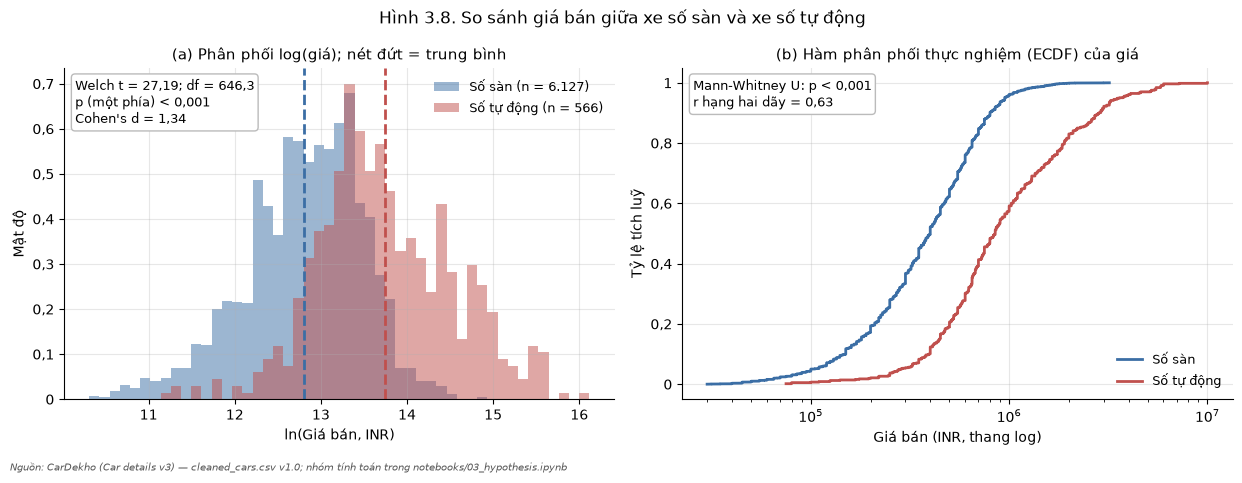

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.6))
bins = np.linspace(df["log_price"].min(), df["log_price"].max(), 50)
for lv, x in zip(ORDER["transmission"], groups_of("transmission")):
    ax1.hist(x, bins=bins, density=True, alpha=0.5, color=COLOR[lv], label=f"{LABEL[lv]} (n = {vn(len(x), 0)})")
    ax1.axvline(x.mean(), color=COLOR[lv], lw=2, ls="--")
ax1.set_xlabel("ln(Giá bán, INR)")
ax1.set_ylabel("Mật độ")
ax1.set_title("(a) Phân phối log(giá); nét đứt = trung bình")
ax1.legend(frameon=False, fontsize=9)
comma_ticks(ax1)
ax1.text(0.02, 0.97, f"Welch t = {vn(kd1['t'])}; df = {vn(kd1['df'], 1)}\n{p_text(kd1['p'], 'p (một phía)')}\n"
         f"Cohen's d = {vn(kd1['d'])}", transform=ax1.transAxes, va="top", fontsize=9,
         bbox=dict(boxstyle="round", fc="white", ec="#BBBBBB"))

for lv in ORDER["transmission"]:
    x = np.sort(df.loc[df["transmission"] == lv, "selling_price"].to_numpy())
    ax2.step(x, np.arange(1, len(x) + 1) / len(x), where="post", color=COLOR[lv], lw=2, label=LABEL[lv])
ax2.set_xscale("log")
ax2.set_xlabel("Giá bán (INR, thang log)")
ax2.set_ylabel("Tỷ lệ tích luỹ")
ax2.set_title("(b) Hàm phân phối thực nghiệm (ECDF) của giá")
ax2.legend(frameon=False, fontsize=9, loc="lower right")
comma_ticks(ax2)
ax2.text(0.02, 0.97, f"Mann-Whitney U: {p_text(kd1['p_mw'])}\nr hạng hai dãy = {vn(kd1['r_rb'])}",
         transform=ax2.transAxes, va="top", fontsize=9, bbox=dict(boxstyle="round", fc="white", ec="#BBBBBB"))
fig.tight_layout(rect=(0, 0, 1, 0.93))
save_fig(fig, "hinh_3_8_hop_so", "Hình 3.8. So sánh giá bán giữa xe số sàn và xe số tự động")

**Kết luận KĐ1.** Bác bỏ $H_0$: giá trung bình (hình học) của xe số tự động **cao hơn** xe số sàn, với chênh lệch rất lớn
(Cohen's $d$ > 0,8). Mann-Whitney U cho cùng kết luận nên kết quả không phụ thuộc giả định chuẩn. Đường ECDF của xe số tự
động nằm bên phải gần như trên toàn miền giá (Hình 3.8b): ở mọi mức phân vị, xe số tự động đều đắt hơn.

## 3. Giá theo nhiên liệu (`fuel_group`) và số đời chủ (`owner`) — KĐ2, KĐ3, KĐ4
Welch ANOVA + Games-Howell (chính); Kruskal-Wallis + Dunn (Holm) kiểm tra lại; $\eta^2 = SS_B/SS_T$ và
$\varepsilon^2 = H/(N-1)$; Spearman với `owner_rank` cho xu hướng theo số đời chủ.

In [9]:
def welch_anova(groups):
    # Welch (1951): F*, df1 = k − 1, df2 = (k² − 1) / (3 Σ (1 − w_i/W)² / (n_i − 1))
    n = np.array([len(g) for g in groups], dtype=float)
    mu = np.array([g.mean() for g in groups])
    var = np.array([g.var(ddof=1) for g in groups])
    k = len(groups)
    w = n / var
    W = w.sum()
    mu_w = (w * mu).sum() / W
    lam = (((1 - w / W) ** 2) / (n - 1)).sum()
    F = ((w * (mu - mu_w) ** 2).sum() / (k - 1)) / (1 + 2 * (k - 2) / (k ** 2 - 1) * lam)
    df1, df2 = k - 1, (k ** 2 - 1) / (3 * lam)
    return F, df1, df2, stats.f.sf(F, df1, df2)


def eta_squared(groups):
    x = np.concatenate(groups)
    ss_b = sum(len(g) * (g.mean() - x.mean()) ** 2 for g in groups)
    return ss_b / ((x - x.mean()) ** 2).sum()


def games_howell(groups, names):
    # Games & Howell (1976): q = |t|·√2 so với phân phối studentized range (k, df Welch–Satterthwaite)
    k = len(groups)
    rows = []
    for i, j in combinations(range(k), 2):
        gi, gj = groups[i], groups[j]
        vi, vj = gi.var(ddof=1) / len(gi), gj.var(ddof=1) / len(gj)
        d = gi.mean() - gj.mean()
        se = np.sqrt(vi + vj)
        dfw = (vi + vj) ** 2 / (vi ** 2 / (len(gi) - 1) + vj ** 2 / (len(gj) - 1))
        p = stats.studentized_range.sf(abs(d / se) * np.sqrt(2), k, dfw)
        half = stats.studentized_range.ppf(1 - ALPHA, k, dfw) / np.sqrt(2) * se
        sp = np.sqrt(((len(gi) - 1) * gi.var(ddof=1) + (len(gj) - 1) * gj.var(ddof=1)) / (len(gi) + len(gj) - 2))
        rows.append({"A": names[i], "B": names[j], "diff": d, "ci_lo": d - half, "ci_hi": d + half,
                     "t": d / se, "df": dfw, "p_gh": p, "cohen_d": d / sp})
    return pd.DataFrame(rows)


def dunn_holm(groups, names):
    # Dunn (1964) có hiệu chỉnh hạng bằng nhau; p hai phía hiệu chỉnh Holm trong từng biến
    x = np.concatenate(groups)
    N = len(x)
    ranks = stats.rankdata(x)
    cut = np.cumsum([0] + [len(g) for g in groups])
    mean_rank = [ranks[cut[i]:cut[i + 1]].mean() for i in range(len(groups))]
    _, t = np.unique(x, return_counts=True)
    tie = (t ** 3 - t).sum() / (12 * (N - 1))
    rows = []
    for i, j in combinations(range(len(groups)), 2):
        se = np.sqrt((N * (N + 1) / 12 - tie) * (1 / len(groups[i]) + 1 / len(groups[j])))
        z = (mean_rank[i] - mean_rank[j]) / se
        rows.append({"A": names[i], "B": names[j], "z_dunn": z, "p_dunn_raw": 2 * stats.norm.sf(abs(z))})
    out = pd.DataFrame(rows)
    out["p_dunn_holm"] = multipletests(out["p_dunn_raw"], method="holm")[1]
    return out


omni, posthoc = {}, []
for col in ["fuel_group", "owner"]:
    gs, names = groups_of(col), ORDER[col]
    N = sum(len(g) for g in gs)
    F, df1, df2, p = welch_anova(gs)
    classic = stats.f_oneway(*gs)
    kw = stats.kruskal(*gs)
    omni[col] = {"F": F, "df1": df1, "df2": df2, "p": p, "F_classic": classic.statistic, "p_classic": classic.pvalue,
                 "eta2": eta_squared(gs), "H": kw.statistic, "p_kw": kw.pvalue, "eps2": kw.statistic / (N - 1)}
    ph = games_howell(gs, names).merge(dunn_holm(gs, names), on=["A", "B"])
    ph.insert(0, "Biến", VAR_LABEL[col])
    posthoc.append(ph)
posthoc = pd.concat(posthoc, ignore_index=True)

bang_3_8 = pd.DataFrame([{
    "Biến": VAR_LABEL[c], "Welch F": o["F"], "df1": o["df1"], "df2": o["df2"], "p (Welch)": o["p"],
    "F cổ điển (tham khảo)": o["F_classic"], "p (cổ điển)": o["p_classic"], "η²": o["eta2"], "Mức η²": muc_eta(o["eta2"]),
    "Kruskal-Wallis H": o["H"], "df (KW)": len(ORDER[c]) - 1, "p (KW)": o["p_kw"], "ε²": o["eps2"]}
    for c, o in omni.items()])
save_table(bang_3_8, "bang_3_8_anova",
           "Bảng 3.8. So sánh log_price theo nhiên liệu và số đời chủ: Welch ANOVA, ANOVA cổ điển, Kruskal-Wallis")

Bảng 3.8. So sánh log_price theo nhiên liệu và số đời chủ: Welch ANOVA, ANOVA cổ điển, Kruskal-Wallis


,Biến,Welch F,df1,df2,p (Welch),F cổ điển (tham khảo),p (cổ điển),η²,Mức η²,Kruskal-Wallis H,df (KW),p (KW),ε²
0,Nhiên liệu,505.060159,2,234.662065,9.462445e-86,486.767020,4.315739e-198,0.127035,vừa,873.002686,2,2.690762e-190,0.130455
1,Số đời chủ,379.145133,3,594.953248,1.322083e-137,394.152716,9.275471e-236,0.150221,lớn,1006.846672,3,5.886750e-218,0.150455


In [10]:
bang_3_9 = pd.DataFrame({
    "Biến": posthoc["Biến"],
    "Cặp (A − B)": posthoc["A"].map(LABEL) + " − " + posthoc["B"].map(LABEL),
    "Δ log_price": posthoc["diff"],
    "KTC 95% (Games-Howell)": [f"[{lo:.3f}; {hi:.3f}]" for lo, hi in zip(posthoc["ci_lo"], posthoc["ci_hi"])],
    "Chênh lệch giá (%)": pct(posthoc["diff"]),
    "p Games-Howell": posthoc["p_gh"],
    "z Dunn": posthoc["z_dunn"],
    "p Dunn (Holm)": posthoc["p_dunn_holm"],
    "Cohen's d": posthoc["cohen_d"],
    "Mức d": posthoc["cohen_d"].map(muc_d),
})
save_table(bang_3_9, "bang_3_9_hau_kiem",
           "Bảng 3.9. Hậu kiểm từng cặp: Games-Howell (chính) và Dunn hiệu chỉnh Holm (kiểm tra lại)")
print("Số cặp Games-Howell có p ≤ 0,05:", (posthoc["p_gh"] <= ALPHA).sum(), "/", len(posthoc),
      "| Số cặp Dunn (Holm) có p ≤ 0,05:", (posthoc["p_dunn_holm"] <= ALPHA).sum(), "/", len(posthoc))
print("Hai phương pháp hậu kiểm cho cùng kết luận ở mọi cặp:",
      ((posthoc["p_gh"] <= ALPHA) == (posthoc["p_dunn_holm"] <= ALPHA)).all())

# KĐ4 — xu hướng theo số đời chủ (owner_rank 1 → 4)
sp_owner = stats.spearmanr(df["owner_rank"], df["log_price"])
kd4 = {"rho": sp_owner.statistic, "p": sp_owner.pvalue}
print(f"\nKĐ4 — Spearman r_s(owner_rank, giá) = {kd4['rho']:.4f}, p = {kd4['p']:.3e} ({muc_r(kd4['rho'])})")
print("Trung bình hình học của giá theo số đời chủ (INR):",
      {LABEL[k]: round(float(np.exp(v))) for k, v in df.groupby("owner")["log_price"].mean()[ORDER["owner"]].items()})

Bảng 3.9. Hậu kiểm từng cặp: Games-Howell (chính) và Dunn hiệu chỉnh Holm (kiểm tra lại)


,Biến,Cặp (A − B),Δ log_price,KTC 95% (Games-Howell),Chênh lệch giá (%),p Games-Howell,z Dunn,p Dunn (Holm),Cohen's d,Mức d
0,Nhiên liệu,Diesel − Xăng (Petrol),0.528766,[0.488; 0.570],69.683727,0.000000e+00,28.745711,3.074289e-181,0.754617,vừa
1,Nhiên liệu,Diesel − CNG/LPG,0.695461,[0.576; 0.815],100.463353,2.686740e-14,9.698380,6.126472e-22,1.014947,lớn
2,Nhiên liệu,Xăng (Petrol) − CNG/LPG,0.166695,[0.047; 0.287],18.139409,3.805822e-03,3.208133,1.335995e-03,0.235418,nhỏ
3,Số đời chủ,1 đời chủ − 2 đời chủ,0.472051,[0.422; 0.522],60.327859,0.000000e+00,23.630607,1.121006e-122,0.687563,vừa
4,Số đời chủ,1 đời chủ − 3 đời chủ,0.770194,[0.685; 0.856],116.018564,4.348744e-13,21.608720,7.435650e-103,1.144265,lớn
5,Số đời chủ,1 đời chủ − ≥ 4 đời chủ,0.992613,[0.835; 1.150],169.827589,0.000000e+00,14.914488,1.061211e-49,1.476416,lớn
6,Số đời chủ,2 đời chủ − 3 đời chủ,0.298144,[0.206; 0.390],34.735513,3.577139e-13,7.384916,4.576479e-13,0.415300,nhỏ
7,Số đời chủ,2 đời chủ − ≥ 4 đời chủ,0.520562,[0.360; 0.681],68.297382,7.194245e-14,6.798195,2.118761e-11,0.719441,vừa
8,Số đời chủ,3 đời chủ − ≥ 4 đời chủ,0.222419,[0.048; 0.397],24.909445,6.243556e-03,2.134495,3.280229e-02,0.313331,nhỏ


Số cặp Games-Howell có p ≤ 0,05: 9 / 9 | Số cặp Dunn (Holm) có p ≤ 0,05: 9 / 9
Hai phương pháp hậu kiểm cho cùng kết luận ở mọi cặp: True

KĐ4 — Spearman r_s(owner_rank, giá) = -0.3860, p = 1.005e-236 (vừa)
Trung bình hình học của giá theo số đời chủ (INR): {'1 đời chủ': 489166, '2 đời chủ': 305104, '3 đời chủ': 226446, '≥ 4 đời chủ': 181288}


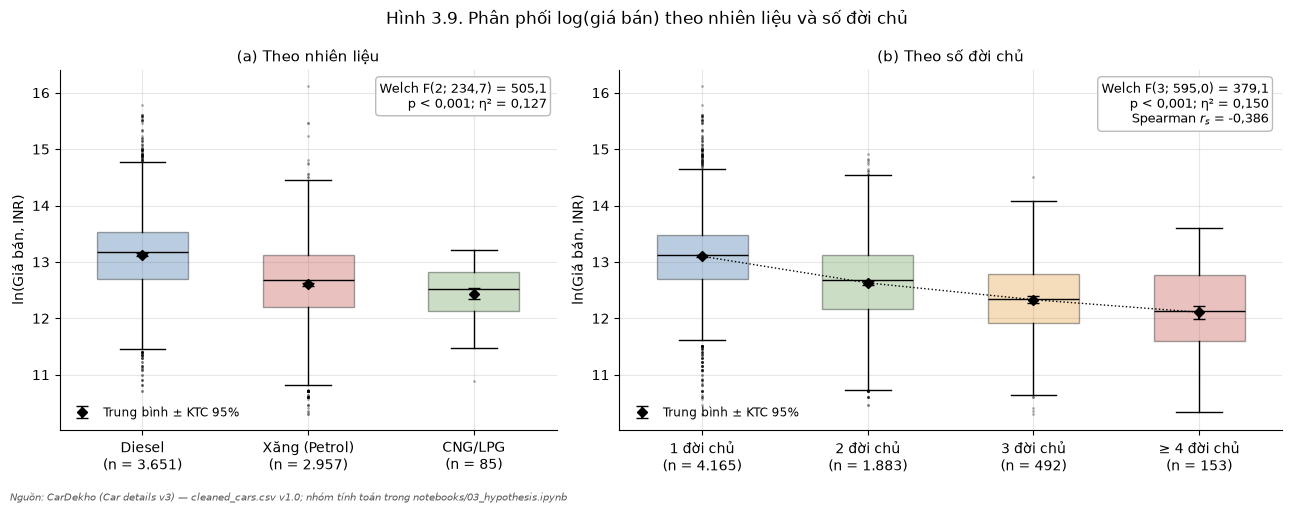

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.9), gridspec_kw={"width_ratios": [3, 4]})
for ax, col, tag in zip(axes, ["fuel_group", "owner"], "ab"):
    gs, levels = groups_of(col), ORDER[col]
    bp = ax.boxplot(gs, widths=0.55, patch_artist=True, showfliers=True,
                    flierprops=dict(marker=".", markersize=2, alpha=0.3), medianprops=dict(color="black"))
    for patch, lv in zip(bp["boxes"], levels):
        patch.set_facecolor(COLOR[lv])
        patch.set_alpha(0.35)
    means = [g.mean() for g in gs]
    ci = [stats.t.ppf(0.975, len(g) - 1) * g.std(ddof=1) / np.sqrt(len(g)) for g in gs]
    pos = np.arange(1, len(levels) + 1)
    ax.errorbar(pos, means, yerr=ci, fmt="D", color="black", ms=5, capsize=4, label="Trung bình ± KTC 95%")
    if col == "owner":
        ax.plot(pos, means, color="black", lw=1, ls=":")
    ax.set_xticks(pos, [f"{LABEL[lv]}\n(n = {vn(len(g), 0)})" for lv, g in zip(levels, gs)])
    ax.set_ylabel("ln(Giá bán, INR)")
    o = omni[col]
    extra = f"\nSpearman $r_s$ = {vn(kd4['rho'], 3)}" if col == "owner" else ""
    ax.set_title(f"({tag}) Theo {VAR_LABEL[col].lower()}")
    ax.text(0.98, 0.97, f"Welch F({vn(o['df1'], 0)}; {vn(o['df2'], 1)}) = {vn(o['F'], 1)}\n"
            f"{p_text(o['p'])}; η² = {vn(o['eta2'], 3)}{extra}", transform=ax.transAxes, ha="right", va="top",
            fontsize=9, bbox=dict(boxstyle="round", fc="white", ec="#BBBBBB"))
    ax.legend(frameon=False, fontsize=8.5, loc="lower left")
fig.tight_layout(rect=(0, 0, 1, 0.93))
save_fig(fig, "hinh_3_9_nhien_lieu_doi_chu", "Hình 3.9. Phân phối log(giá bán) theo nhiên liệu và số đời chủ")

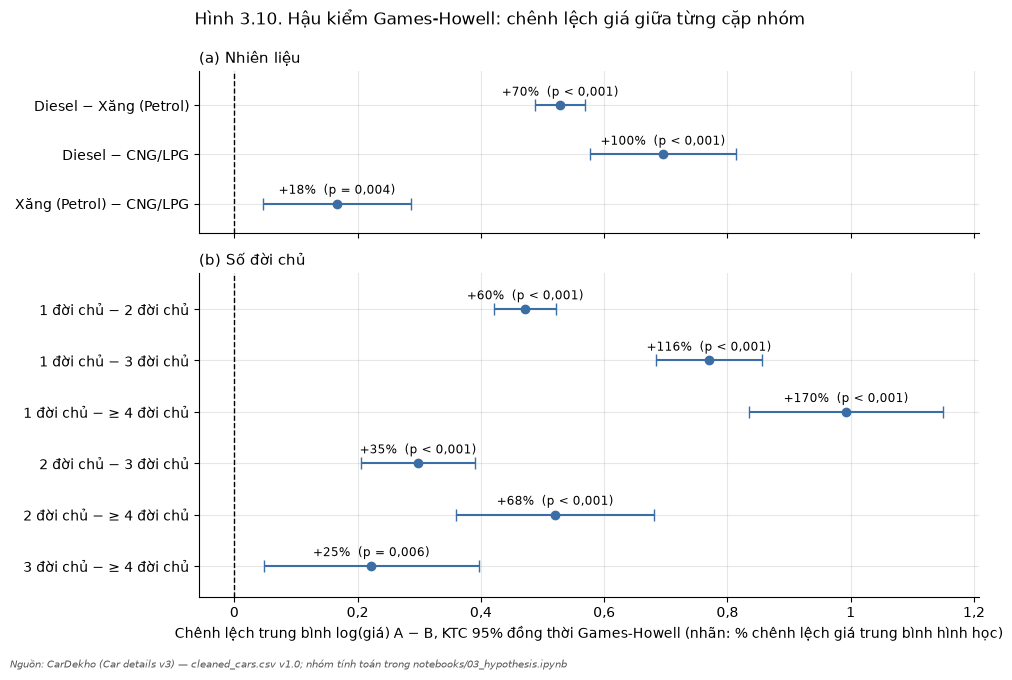

In [12]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6.6), gridspec_kw={"height_ratios": [3, 6]}, sharex=True)
for ax, col, tag in zip(axes, ["fuel_group", "owner"], "ab"):
    sub = posthoc[posthoc["Biến"] == VAR_LABEL[col]].iloc[::-1]
    y = np.arange(len(sub))
    sig = sub["p_gh"] <= ALPHA
    ax.errorbar(sub["diff"], y, xerr=[sub["diff"] - sub["ci_lo"], sub["ci_hi"] - sub["diff"]], fmt="o",
                color="#3B6EA5", ecolor="#3B6EA5", capsize=4, ms=6)
    ax.axvline(0, color="black", lw=1, ls="--")
    ax.set_yticks(y, [f"{LABEL[a]} − {LABEL[b]}" for a, b in zip(sub["A"], sub["B"])])
    for yi, (d, p) in enumerate(zip(sub["diff"], sub["p_gh"])):
        ax.annotate(f"{pct(d):+.0f}%  ({p_text(p)})", (d, yi), xytext=(0, 7),
                    textcoords="offset points", ha="center", fontsize=8.5)
    ax.set_title(f"({tag}) {VAR_LABEL[col]}", loc="left")
    ax.set_ylim(-0.6, len(sub) - 0.3)
comma_ticks(axes[1], "x")
axes[1].set_xlabel("Chênh lệch trung bình log(giá) A − B, KTC 95% đồng thời Games-Howell "
                   "(nhãn: % chênh lệch giá trung bình hình học)")
fig.tight_layout(rect=(0, 0, 1, 0.94))
save_fig(fig, "hinh_3_10_games_howell", "Hình 3.10. Hậu kiểm Games-Howell: chênh lệch giá giữa từng cặp nhóm")

**Kết luận KĐ2 – KĐ4.**

* **Nhiên liệu (KĐ2):** bác bỏ $H_0$; Games-Howell cho thấy cả ba cặp đều khác nhau: Diesel đắt nhất, rồi đến xăng, thấp
  nhất là CNG/LPG. Hệ số $\eta^2$ ở mức vừa (gần ngưỡng lớn).
* **Số đời chủ (KĐ3):** bác bỏ $H_0$; cả sáu cặp đều khác nhau, giá giảm dần khi số đời chủ tăng; $\eta^2$ ở mức lớn.
* **Xu hướng (KĐ4):** $r_s$ âm, mức vừa: xe qua càng nhiều đời chủ thì giá càng thấp.
* Kruskal-Wallis + Dunn (Holm) cho cùng kết luận ở mọi cặp (dòng in dưới Bảng 3.9), nên kết luận vững với giả định.

## 4. Chi-squared: `fuel_group` × `transmission` (KĐ5)
Kiểm tra tần số kỳ vọng ≥ 5, Cramér's V; phần dư chuẩn hoá điều chỉnh
$(O_{ij}-E_{ij})/\sqrt{E_{ij}(1-p_{i\cdot})(1-p_{\cdot j})}$ cho biết ô nào đóng góp vào sự phụ thuộc ($|r| > 1{,}96$).

In [13]:
ct = pd.crosstab(df["fuel_group"], df["transmission"]).loc[ORDER["fuel_group"], ORDER["transmission"]]
chi = stats.chi2_contingency(ct, correction=False)
E = pd.DataFrame(chi.expected_freq, index=ct.index, columns=ct.columns)
n_all = ct.to_numpy().sum()
row_p = ct.sum(axis=1).to_numpy()[:, None] / n_all
col_p = ct.sum(axis=0).to_numpy()[None, :] / n_all
adj_res = (ct - E) / np.sqrt(E * (1 - row_p) * (1 - col_p))
cramer_v = np.sqrt(chi.statistic / (n_all * (min(ct.shape) - 1)))
print(f"Tần số kỳ vọng nhỏ nhất = {E.to_numpy().min():.2f}; số ô có E < 5: {(E.to_numpy() < 5).sum()} / {E.size}")

# Kiểm tra độ nhạy: bỏ nhóm CNG/LPG (không có xe số tự động), bảng 2×2 Diesel – Petrol
ct2 = ct.loc[["Diesel", "Petrol"]]
chi2x2 = stats.chi2_contingency(ct2, correction=False)
fisher = stats.fisher_exact(ct2.to_numpy())
phi = np.sqrt(chi2x2.statistic / ct2.to_numpy().sum())
kd5 = {"chi2": chi.statistic, "df": chi.dof, "p": chi.pvalue, "V": cramer_v, "E_min": E.to_numpy().min(),
       "chi2_2x2": chi2x2.statistic, "p_2x2": chi2x2.pvalue, "p_fisher": fisher.pvalue, "phi_2x2": phi}

ty_le_td = ct["Automatic"] / ct.sum(axis=1) * 100
bang_3_10 = pd.DataFrame({
    "Nhiên liệu": [LABEL[i] for i in ct.index],
    "Số sàn: O (E)": [f"{o} ({e:.1f})" for o, e in zip(ct["Manual"], E["Manual"])],
    "Số tự động: O (E)": [f"{o} ({e:.1f})" for o, e in zip(ct["Automatic"], E["Automatic"])],
    "Tổng": ct.sum(axis=1).to_numpy(),
    "% số tự động": ty_le_td.to_numpy(),
    "Phần dư chuẩn hoá điều chỉnh (số tự động)": adj_res["Automatic"].to_numpy(),
})
save_table(bang_3_10, "bang_3_10_bang_tiep_lien",
           "Bảng 3.10. Bảng tiếp liên nhiên liệu × hộp số: tần số quan sát O và kỳ vọng E")
print(f"χ²({chi.dof}) = {chi.statistic:.3f}, p = {chi.pvalue:.4f}, Cramér's V = {cramer_v:.4f} ({muc_r(cramer_v)})")
print(f"Độ nhạy Diesel – Petrol (2×2): χ²(1) = {chi2x2.statistic:.3f}, p = {chi2x2.pvalue:.4f}; "
      f"Fisher p = {fisher.pvalue:.4f}; φ = {phi:.4f}")

Tần số kỳ vọng nhỏ nhất = 7.19; số ô có E < 5: 0 / 6
Bảng 3.10. Bảng tiếp liên nhiên liệu × hộp số: tần số quan sát O và kỳ vọng E


,Nhiên liệu,Số sàn: O (E),Số tự động: O (E),Tổng,% số tự động,Phần dư chuẩn hoá điều chỉnh (số tự động)
0,Diesel,3358 (3342.2),293 (308.8),3651,8.025199,-1.389643
1,Xăng (Petrol),2684 (2706.9),273 (250.1),2957,9.232330,2.029242
2,CNG/LPG,85 (77.8),0 (7.2),85,0.000000,-2.820130


χ²(2) = 11.028, p = 0.0040, Cramér's V = 0.0406 (không đáng kể)
Độ nhạy Diesel – Petrol (2×2): χ²(1) = 3.040, p = 0.0812; Fisher p = 0.0847; φ = 0.0214


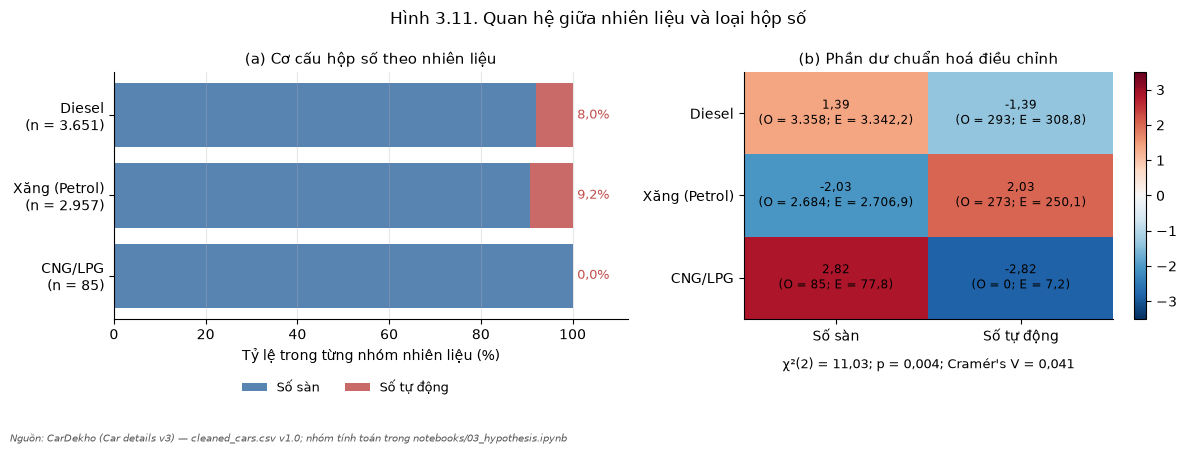

In [14]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.3), gridspec_kw={"width_ratios": [1.25, 1]})
prop = ct.div(ct.sum(axis=1), axis=0) * 100
labels = [f"{LABEL[i]}\n(n = {vn(ct.loc[i].sum(), 0)})" for i in ct.index]
ax1.barh(labels, prop["Manual"], color=COLOR["Manual"], alpha=0.85, label=LABEL["Manual"])
ax1.barh(labels, prop["Automatic"], left=prop["Manual"], color=COLOR["Automatic"], alpha=0.85,
         label=LABEL["Automatic"])
for yi, v in enumerate(prop["Automatic"]):
    ax1.text(101, yi, f"{vn(v, 1)}%", va="center", fontsize=9, color=COLOR["Automatic"])
ax1.set_xlim(0, 112)
ax1.invert_yaxis()
ax1.set_xlabel("Tỷ lệ trong từng nhóm nhiên liệu (%)")
ax1.set_title("(a) Cơ cấu hộp số theo nhiên liệu")
ax1.legend(frameon=False, fontsize=9, loc="upper center", bbox_to_anchor=(0.45, -0.2), ncol=2)
ax1.grid(axis="y", visible=False)

im = ax2.imshow(adj_res.to_numpy(), cmap="RdBu_r", vmin=-3.5, vmax=3.5, aspect="auto")
ax2.set_xticks(range(2), [LABEL[c] for c in ct.columns])
ax2.set_yticks(range(3), [LABEL[i] for i in ct.index])
for i in range(3):
    for j in range(2):
        ax2.text(j, i, f"{vn(adj_res.iat[i, j])}\n(O = {vn(ct.iat[i, j], 0)}; E = {vn(E.iat[i, j], 1)})",
                 ha="center", va="center", fontsize=8.5)
ax2.grid(False)
ax2.set_title("(b) Phần dư chuẩn hoá điều chỉnh")
fig.colorbar(im, ax=ax2, fraction=0.05)
ax2.text(0.5, -0.2, f"χ²({kd5['df']}) = {vn(kd5['chi2'])}; {p_text(kd5['p'])}; Cramér's V = {vn(kd5['V'], 3)}",
         transform=ax2.transAxes, ha="center", fontsize=9)
fig.tight_layout(rect=(0, 0, 1, 0.92))
save_fig(fig, "hinh_3_11_chi_binh_phuong", "Hình 3.11. Quan hệ giữa nhiên liệu và loại hộp số")

**Kết luận KĐ5.** Mọi tần số kỳ vọng đều ≥ 5 nên kiểm định Chi-bình phương hợp lệ, không cần Fisher cho bảng 3×2.
Kiểm định bác bỏ $H_0$ nhưng Cramér's $V$ rất nhỏ (< 0,1): sự phụ thuộc có ý nghĩa thống kê nhưng **không đáng kể về
thực tế**. Phần dư (Hình 3.11b) cho thấy sự phụ thuộc đến chủ yếu từ nhóm CNG/LPG không có xe số tự động nào; khi chỉ xét
Diesel và xăng (bảng 2×2), tỷ lệ số tự động gần như như nhau và không còn khác biệt có ý nghĩa.

## 5. Bảng tổng hợp
H0/H1 · kiểm định · thống kê · p-value (đã hiệu chỉnh Holm) · hệ số ảnh hưởng · kết luận. Ghi chú: kiểm định chưa kiểm soát yếu tố gây nhiễu (hãng, tuổi xe) — xem hồi quy của TV4.

In [15]:
fam = pd.DataFrame([
    {"KĐ": "KĐ1", "Câu hỏi": "CH2", "H0": "μ(tự động) = μ(số sàn)", "H1": "μ(tự động) > μ(số sàn)",
     "Kiểm định (lý do)": "Welch t-test một phía (phương sai khác nhau, cỡ nhóm lệch)",
     "Thống kê": f"t = {vn(kd1['t'])}; df = {vn(kd1['df'], 1)}", "p": kd1["p"],
     "Hệ số ảnh hưởng": f"d = {vn(kd1['d'])}", "Mức": muc_d(kd1["d"]),
     "Kiểm tra lại": f"Mann-Whitney U: p {fmt_p(kd1['p_mw'])}; r = {vn(kd1['r_rb'])}"},
    {"KĐ": "KĐ2", "Câu hỏi": "CH3", "H0": "μ bằng nhau theo 3 nhóm nhiên liệu", "H1": "Ít nhất một cặp khác nhau",
     "Kiểm định (lý do)": "Welch ANOVA + Games-Howell (phương sai khác nhau, CNG/LPG chỉ 85 xe)",
     "Thống kê": f"F = {vn(omni['fuel_group']['F'], 1)}; df = ({vn(omni['fuel_group']['df1'], 0)}; "
                 f"{vn(omni['fuel_group']['df2'], 1)})", "p": omni["fuel_group"]["p"],
     "Hệ số ảnh hưởng": f"η² = {vn(omni['fuel_group']['eta2'], 3)}", "Mức": muc_eta(omni["fuel_group"]["eta2"]),
     "Kiểm tra lại": f"Kruskal-Wallis: H = {vn(omni['fuel_group']['H'], 1)}; p {fmt_p(omni['fuel_group']['p_kw'])}; "
                     f"ε² = {vn(omni['fuel_group']['eps2'], 3)}"},
    {"KĐ": "KĐ3", "Câu hỏi": "CH3", "H0": "μ bằng nhau theo 4 mức số đời chủ", "H1": "Ít nhất một cặp khác nhau",
     "Kiểm định (lý do)": "Welch ANOVA + Games-Howell (phương sai khác nhau, cỡ nhóm 153 – 4.165)",
     "Thống kê": f"F = {vn(omni['owner']['F'], 1)}; df = ({vn(omni['owner']['df1'], 0)}; "
                 f"{vn(omni['owner']['df2'], 1)})", "p": omni["owner"]["p"],
     "Hệ số ảnh hưởng": f"η² = {vn(omni['owner']['eta2'], 3)}", "Mức": muc_eta(omni["owner"]["eta2"]),
     "Kiểm tra lại": f"Kruskal-Wallis: H = {vn(omni['owner']['H'], 1)}; p {fmt_p(omni['owner']['p_kw'])}; "
                     f"ε² = {vn(omni['owner']['eps2'], 3)}"},
    {"KĐ": "KĐ4", "Câu hỏi": "CH3", "H0": "ρs(owner_rank, giá) = 0", "H1": "ρs ≠ 0",
     "Kiểm định (lý do)": "Tương quan hạng Spearman (owner là biến thứ bậc)",
     "Thống kê": f"r_s = {vn(kd4['rho'], 3)}; n = {vn(len(df), 0)}", "p": kd4["p"],
     "Hệ số ảnh hưởng": f"r_s = {vn(kd4['rho'], 3)}", "Mức": muc_r(kd4["rho"]), "Kiểm tra lại": "—"},
    {"KĐ": "KĐ5", "Câu hỏi": "CH4", "H0": "Nhiên liệu và hộp số độc lập", "H1": "Không độc lập",
     "Kiểm định (lý do)": f"Chi-bình phương (mọi E ≥ 5, nhỏ nhất {vn(kd5['E_min'], 2)})",
     "Thống kê": f"χ² = {vn(kd5['chi2'])}; df = {kd5['df']}", "p": kd5["p"],
     "Hệ số ảnh hưởng": f"V = {vn(kd5['V'], 3)}", "Mức": muc_r(kd5["V"]),
     "Kiểm tra lại": f"Diesel – Petrol 2×2: Fisher p = {fmt_p(kd5['p_fisher'])}"},
])
fam["p (Holm)"] = multipletests(fam["p"], alpha=ALPHA, method="holm")[1]
fam["Quyết định"] = np.where(fam["p (Holm)"] <= ALPHA, "Bác bỏ H0", "Chưa bác bỏ H0")
geo = df.groupby("owner")["log_price"].mean()
ket_luan = {
    "KĐ1": f"Xe số tự động đắt hơn xe số sàn khoảng {vn(pct(kd1['diff']), 0)}% (gấp {vn(np.exp(kd1['diff']))} lần, "
           f"KTC 95%: {vn(np.exp(kd1['ci'][0]))} – {vn(np.exp(kd1['ci'][1]))} lần); chênh lệch lớn",
    "KĐ2": "Giá khác nhau theo nhiên liệu: Diesel > xăng > CNG/LPG, cả 3 cặp đều khác nhau (Games-Howell)",
    "KĐ3": "Giá khác nhau theo số đời chủ: cả 6 cặp đều khác nhau (Games-Howell)",
    "KĐ4": f"Giá giảm dần theo số đời chủ (trung bình hình học từ {vn(np.exp(geo['First Owner']), 0)} INR "
           f"xuống {vn(np.exp(geo['Fourth & Above Owner']), 0)} INR)",
    "KĐ5": "Có phụ thuộc về mặt thống kê nhưng rất yếu, chủ yếu do xe CNG/LPG không có số tự động",
}
fam["Kết luận thực tế"] = fam["KĐ"].map(ket_luan)
bang_3_11 = fam[["KĐ", "Câu hỏi", "H0", "H1", "Kiểm định (lý do)", "Thống kê", "p", "p (Holm)", "Quyết định",
                 "Hệ số ảnh hưởng", "Mức", "Kiểm tra lại", "Kết luận thực tế"]]
save_table(bang_3_11, "bang_3_11_tong_hop",
           "Bảng 3.11. Tổng hợp kết quả kiểm định giả thuyết (α = 0,05; p hiệu chỉnh Holm cho họ KĐ1 – KĐ5)")

Bảng 3.11. Tổng hợp kết quả kiểm định giả thuyết (α = 0,05; p hiệu chỉnh Holm cho họ KĐ1 – KĐ5)


,KĐ,Câu hỏi,H0,H1,Kiểm định (lý do),Thống kê,p,p (Holm),Quyết định,Hệ số ảnh hưởng,Mức,Kiểm tra lại,Kết luận thực tế
0,KĐ1,CH2,μ(tự động) = μ(số sàn),μ(tự động) > μ(số sàn),"Welch t-test một phía (phương sai khác nhau, c...","t = 27,19; df = 646,3",1.985406e-109,5.956218e-109,Bác bỏ H0,"d = 1,34",lớn,"Mann-Whitney U: p < 0,001; r = 0,63",Xe số tự động đắt hơn xe số sàn khoảng 156% (g...
1,KĐ2,CH3,μ bằng nhau theo 3 nhóm nhiên liệu,Ít nhất một cặp khác nhau,Welch ANOVA + Games-Howell (phương sai khác nh...,"F = 505,1; df = (2; 234,7)",9.462445e-86,1.892489e-85,Bác bỏ H0,"η² = 0,127",vừa,"Kruskal-Wallis: H = 873,0; p < 0,001; ε² = 0,130",Giá khác nhau theo nhiên liệu: Diesel > xăng >...
2,KĐ3,CH3,μ bằng nhau theo 4 mức số đời chủ,Ít nhất một cặp khác nhau,Welch ANOVA + Games-Howell (phương sai khác nh...,"F = 379,1; df = (3; 595,0)",1.322083e-137,5.288332e-137,Bác bỏ H0,"η² = 0,150",lớn,"Kruskal-Wallis: H = 1.006,8; p < 0,001; ε² = 0...",Giá khác nhau theo số đời chủ: cả 6 cặp đều kh...
3,KĐ4,CH3,"ρs(owner_rank, giá) = 0",ρs ≠ 0,Tương quan hạng Spearman (owner là biến thứ bậc),"r_s = -0,386; n = 6.693",1.005023e-236,5.025113e-236,Bác bỏ H0,"r_s = -0,386",vừa,—,Giá giảm dần theo số đời chủ (trung bình hình ...
4,KĐ5,CH4,Nhiên liệu và hộp số độc lập,Không độc lập,"Chi-bình phương (mọi E ≥ 5, nhỏ nhất 7,19)","χ² = 11,03; df = 2",4.029194e-03,4.029194e-03,Bác bỏ H0,"V = 0,041",không đáng kể,"Diesel – Petrol 2×2: Fisher p = 0,085","Có phụ thuộc về mặt thống kê nhưng rất yếu, ch..."


## 6. Yếu tố gây nhiễu và lưu ý khi diễn giải

Các kiểm định trên chỉ cho thấy **có khác biệt** giữa các nhóm, chưa tách được tác động riêng của từng yếu tố. Bảng 3.12
cho thấy các nhóm khác nhau rõ về tuổi xe, số km và công suất — những biến cũng ảnh hưởng mạnh đến giá. Ví dụ xe qua nhiều
đời chủ thường là xe cũ hơn và đã chạy nhiều hơn; xe số tự động thường mạnh hơn và thuộc phân khúc cao hơn. Mức độ ảnh hưởng
riêng của hộp số, nhiên liệu, số đời chủ khi giữ các yếu tố khác không đổi được ước lượng trong mô hình hồi quy của TV4
(mục 3.3).

In [16]:
rows = []
for col in ORDER:
    for lv in ORDER[col]:
        g = df[df[col] == lv]
        rows.append({"Biến": VAR_LABEL[col], "Nhóm": LABEL[lv], "n": len(g),
                     "Tuổi xe TB (năm)": g["car_age"].mean(), "km_driven trung vị": g["km_driven"].median(),
                     "max_power trung vị (bhp)": g["max_power"].median(),
                     "% số tự động": np.nan if col == "transmission" else (g["transmission"] == "Automatic").mean() * 100,
                     "Giá trung vị (INR)": g["selling_price"].median()})
bang_3_12 = pd.DataFrame(rows)
save_table(bang_3_12, "bang_3_12_gay_nhieu",
           "Bảng 3.12. Đặc điểm các nhóm có thể gây nhiễu kết quả kiểm định")
rho_age = stats.spearmanr(df["owner_rank"], df["car_age"]).statistic
print(f"Spearman r_s(owner_rank, car_age) = {rho_age:.3f}")

Bảng 3.12. Đặc điểm các nhóm có thể gây nhiễu kết quả kiểm định


,Biến,Nhóm,n,Tuổi xe TB (năm),km_driven trung vị,max_power trung vị (bhp),% số tự động,Giá trung vị (INR)
0,Hộp số,Số sàn,6127,6.556390,70000.0,81.80,NaN,400000.0
1,Hộp số,Số tự động,566,4.565371,42000.0,126.20,NaN,850000.0
2,Nhiên liệu,Diesel,3651,6.203232,80000.0,88.73,8.025199,525000.0
3,Nhiên liệu,Xăng (Petrol),2957,6.609401,49455.0,78.90,9.232330,320000.0
4,Nhiên liệu,CNG/LPG,85,6.623529,70000.0,58.30,0.000000,275000.0
5,Số đời chủ,1 đời chủ,4165,4.964226,50000.0,82.00,10.348139,500000.0
6,Số đời chủ,2 đời chủ,1883,8.158258,80000.0,78.00,5.947955,320000.0
7,Số đời chủ,3 đời chủ,492,10.018293,97000.0,75.00,3.658537,229999.0
8,Số đời chủ,≥ 4 đời chủ,153,11.686275,100000.0,78.90,3.267974,185000.0


Spearman r_s(owner_rank, car_age) = 0.502


## 7. Số liệu cho báo cáo (mục 3.2)
Mọi con số trong `report/chapters/03_ket_qua.md` (mục 3.2) lấy từ ô dưới đây, đã định dạng kiểu Việt Nam.

In [17]:
o_f, o_o = omni["fuel_group"], omni["owner"]
print("== Giả định ==")
print(f"|độ lệch| lớn nhất = {vn(bang_3_6['Độ lệch'].abs().max(), 2)}; |độ nhọn dư| lớn nhất = "
      f"{vn(bang_3_6['Độ nhọn dư'].abs().max(), 2)}; Shapiro bác bỏ {(bang_3_6['Shapiro p'] <= ALPHA).sum()}/9 nhóm")
for _, r in bang_3_7.iterrows():
    print(f"Levene {r['Biến']}: W = {vn(r['W (Brown-Forsythe)'])}; p {fmt_p(r['p'])}; "
          f"ĐLC max/min = {vn(r['ĐLC lớn nhất / nhỏ nhất'])}; cỡ nhóm max/min = {vn(r['Cỡ nhóm lớn nhất / nhỏ nhất'], 1)}")
print("\n== KĐ1 ==")
for lv in ORDER["transmission"]:
    r = mo_ta.loc[lv]
    print(f"{LABEL[lv]}: n = {vn(r['n'], 0)}; TB log = {vn(r['tb_log'], 3)}; ĐLC = {vn(r['dlc_log'], 3)}; "
          f"TB hình học = {vn(r['tb_hinh_hoc_gia'], 0)} INR; trung vị = {vn(r['trung_vi_gia'], 0)} INR")
print(f"t = {vn(kd1['t'])}; df = {vn(kd1['df'], 1)}; p {fmt_p(kd1['p'])} (p = {kd1['p']:.1e}); Δ = {vn(kd1['diff'], 3)} "
      f"[{vn(kd1['ci'][0], 3)}; {vn(kd1['ci'][1], 3)}]; gấp {vn(np.exp(kd1['diff']))} lần "
      f"[{vn(np.exp(kd1['ci'][0]))}; {vn(np.exp(kd1['ci'][1]))}]; +{vn(pct(kd1['diff']), 1)}% "
      f"[{vn(pct(kd1['ci'][0]), 1)}%; {vn(pct(kd1['ci'][1]), 1)}%]; d = {vn(kd1['d'])}")
print(f"Mann-Whitney U = {vn(kd1['U'], 1)}; p {fmt_p(kd1['p_mw'])}; r = {vn(kd1['r_rb'], 3)}")
print("\n== KĐ2, KĐ3 ==")
for c, o in omni.items():
    print(f"{VAR_LABEL[c]}: Welch F({vn(o['df1'], 0)}; {vn(o['df2'], 1)}) = {vn(o['F'], 1)}; p {fmt_p(o['p'])}; "
          f"F cổ điển = {vn(o['F_classic'], 1)}; η² = {vn(o['eta2'], 3)}; H = {vn(o['H'], 1)}; p {fmt_p(o['p_kw'])}; "
          f"ε² = {vn(o['eps2'], 3)}")
for c in ["fuel_group", "owner"]:
    print(f"  Trung bình hình học theo {VAR_LABEL[c].lower()} (INR):",
          "; ".join(f"{LABEL[k]} {vn(np.exp(v), 0)}" for k, v in df.groupby(c)["log_price"].mean()[ORDER[c]].items()))
for _, r in posthoc.iterrows():
    print(f"  {r['Biến']}: {LABEL[r['A']]} − {LABEL[r['B']]}: Δ = {vn(r['diff'], 3)} [{vn(r['ci_lo'], 3)}; "
          f"{vn(r['ci_hi'], 3)}] ({vn(pct(r['diff']), 1)}%); p_GH {fmt_p(r['p_gh'])}; "
          f"p_Dunn,Holm {fmt_p(r['p_dunn_holm'])}; d = {vn(r['cohen_d'])}")
print("\n== KĐ4 ==")
print(f"r_s = {vn(kd4['rho'], 3)}; p {fmt_p(kd4['p'])}; r_s(owner_rank, car_age) = {vn(rho_age, 3)}")
print("\n== KĐ5 ==")
print(f"χ²({kd5['df']}) = {vn(kd5['chi2'])}; p = {vn(kd5['p'], 4)}; V = {vn(kd5['V'], 3)}; E nhỏ nhất = "
      f"{vn(kd5['E_min'], 2)}; % số tự động: " + "; ".join(f"{LABEL[k]} {vn(v, 1)}%" for k, v in ty_le_td.items()))
print(f"2×2 Diesel – Petrol: χ²(1) = {vn(kd5['chi2_2x2'])}; p = {vn(kd5['p_2x2'], 3)}; Fisher p = "
      f"{vn(kd5['p_fisher'], 3)}; φ = {vn(kd5['phi_2x2'], 3)}")
print("\n== Holm ==")
print("; ".join(f"{r['KĐ']}: p = {r['p']:.2e} → p_Holm = {r['p (Holm)']:.2e}" for _, r in fam.iterrows()))
print("\n== Bảng 3.12 ==")
for _, r in bang_3_12.iterrows():
    print(f"{r['Biến']} – {r['Nhóm']}: tuổi TB {vn(r['Tuổi xe TB (năm)'], 1)}; km trung vị {vn(r['km_driven trung vị'], 0)}; "
          f"công suất trung vị {vn(r['max_power trung vị (bhp)'], 1)} bhp; % tự động "
          f"{'—' if np.isnan(r['% số tự động']) else vn(r['% số tự động'], 1)}; giá trung vị {vn(r['Giá trung vị (INR)'], 0)}")

== Giả định ==
|độ lệch| lớn nhất = 0,77; |độ nhọn dư| lớn nhất = 1,58; Shapiro bác bỏ 8/9 nhóm
Levene Hộp số: W = 18,16; p < 0,001; ĐLC max/min = 1,15; cỡ nhóm max/min = 10,8
Levene Nhiên liệu: W = 10,90; p < 0,001; ĐLC max/min = 1,59; cỡ nhóm max/min = 43,0
Levene Số đời chủ: W = 13,96; p < 0,001; ĐLC max/min = 1,10; cỡ nhóm max/min = 27,2

== KĐ1 ==
Số sàn: n = 6.127; TB log = 12,809; ĐLC = 0,691; TB hình học = 365.464 INR; trung vị = 400.000 INR
Số tự động: n = 566; TB log = 13,748; ĐLC = 0,794; TB hình học = 934.796 INR; trung vị = 850.000 INR
t = 27,19; df = 646,3; p < 0,001 (p = 2.0e-109); Δ = 0,939 [0,871; 1,007]; gấp 2,56 lần [2,39; 2,74]; +155,8% [139,0%; 173,7%]; d = 1,34
Mann-Whitney U = 2.829.186,5; p < 0,001; r = 0,632

== KĐ2, KĐ3 ==
Nhiên liệu: Welch F(2; 234,7) = 505,1; p < 0,001; F cổ điển = 486,8; η² = 0,127; H = 873,0; p < 0,001; ε² = 0,130
Số đời chủ: Welch F(3; 595,0) = 379,1; p < 0,001; F cổ điển = 394,2; η² = 0,150; H = 1.006,8; p < 0,001; ε² = 0,150
  Trung bìn

## 8. Kiểm tra chéo (không bắt buộc)
So sánh các hàm tự cài ở trên với `pingouin` và `scikit-posthocs` (có trong `requirements.txt`). Nếu môi trường chưa cài hai
gói này (ví dụ Kaggle không có internet), ô sẽ bỏ qua — kết quả phía trên không phụ thuộc vào chúng.

In [18]:
try:
    import pingouin as pg
    import scikit_posthocs as sk
except ImportError as e:
    print("Bỏ qua kiểm tra chéo:", e)
else:
    for col in ["fuel_group", "owner"]:
        w = pg.welch_anova(data=df, dv="log_price", between=col).iloc[0]
        assert np.isclose(w["F"], omni[col]["F"]) and np.isclose(w["ddof2"], omni[col]["df2"])
        assert np.isclose(w["np2"], omni[col]["eta2"])
        gh = pg.pairwise_gameshowell(data=df, dv="log_price", between=col)
        mine = posthoc[posthoc["Biến"] == VAR_LABEL[col]]
        for _, r in gh.iterrows():
            row = mine[((mine["A"] == r["A"]) & (mine["B"] == r["B"])) | ((mine["A"] == r["B"]) & (mine["B"] == r["A"]))].iloc[0]
            assert np.isclose(abs(r["diff"]), abs(row["diff"])) and np.isclose(r["pval"], row["p_gh"], atol=1e-6)
        dn = sk.posthoc_dunn(df, val_col="log_price", group_col=col, p_adjust="holm")
        for _, r in mine.iterrows():
            assert np.isclose(dn.loc[r["A"], r["B"]], r["p_dunn_holm"], rtol=1e-6, atol=1e-300)
    t = pg.ttest(a, m, correction=True, alternative="greater").iloc[0]
    assert np.isclose(t["T"], kd1["t"]) and np.isclose(t["cohen_d"], kd1["d"])
    print("Khớp với pingouin", pg.__version__, "và scikit-posthocs", sk.__version__,
          ": Welch ANOVA, η², Games-Howell, Dunn (Holm), Welch t, Cohen's d.")

Khớp với pingouin 0.7.0 và scikit-posthocs 0.18.0 : Welch ANOVA, η², Games-Howell, Dunn (Holm), Welch t, Cohen's d.
